# Simulation for Section 6: the quantum attack discrimination problem

This notebook reproduces the controlled simulation reported in the survey *Quantum Networks Still Need Watching* (Section 6.4, Figure 5).
It needs no uploads: it only uses `numpy`, `pandas`, and `matplotlib`. Running all cells writes JSON and CSV files to `results/` and
checks the output against the numbers quoted in the paper.

**Model.** A BB84-like link reports one QBER estimate per block of `N_BITS` sifted bits. The natural QBER drifts slowly
(sinusoid + AR(1) noise). From block `T_ATTACK` an intercept-resend adversary attacks a fraction `f` of the pulses, which adds about `0.25 f` to the QBER.
Three detectors are compared: the 11% abort rule, a fixed threshold calibrated to a target false-alarm rate on attack-free runs,
and an adaptive rolling-median/MAD detector calibrated to the same false-alarm rate. All data are synthetic.

In [1]:
# Cell 1: imports and output folders
import os, json, time, zipfile
import numpy as np
import pandas as pd

OUT = "results"          # JSON/CSV results (commit these to GitHub)
FIGDATA = "results/figdata"   # small CSV files read by the LaTeX figure (pgfplots)
os.makedirs(OUT, exist_ok=True); os.makedirs(FIGDATA, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


In [2]:
# Cell 2: parameters
COMMON = dict(
    N_BITS=10_000,            # sifted bits per QBER estimate (one block)
    AR_STD=0.002,             # AR(1) innovation standard deviation (environment)
    AR_PHI=0.9,               # AR(1) coefficient
    T=1200,                   # blocks per run
    T_ATTACK=800,             # attack starts at this block
    HORIZON=50,               # blocks allowed to detect after onset
    RUN=3,                    # consecutive exceedances required by the adaptive rule
    TARGET_FA=1e-3,           # false-alarm rate per block used for calibration
    N_CLEAN=200,              # attack-free runs used for calibration
    R=300,                    # runs per attacked fraction
    FRACTIONS=[0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.60, 0.80, 1.0],
    SEED=7,                   # seed of the main experiment
    TRACE_SEED=11,            # seed of the single run drawn in Figure 5(a)
)
SCENARIOS = {                 # environmental variation of the channel
    "strong": dict(E0=0.040, DRIFT=0.030, PERIOD=800, WIN=40),    # large drift (Figure 5)
    "mild":   dict(E0=0.020, DRIFT=0.010, PERIOD=400, WIN=100),   # small drift (quoted in the text)
}
print(COMMON); print(SCENARIOS)

{'N_BITS': 10000, 'AR_STD': 0.002, 'AR_PHI': 0.9, 'T': 1200, 'T_ATTACK': 800, 'HORIZON': 50, 'RUN': 3, 'TARGET_FA': 0.001, 'N_CLEAN': 200, 'R': 300, 'FRACTIONS': [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.6, 0.8, 1.0], 'SEED': 7, 'TRACE_SEED': 11}
{'strong': {'E0': 0.04, 'DRIFT': 0.03, 'PERIOD': 800, 'WIN': 40}, 'mild': {'E0': 0.02, 'DRIFT': 0.01, 'PERIOD': 400, 'WIN': 100}}


In [3]:
# Cell 3: simulation functions
def natural_qber(rng, P):
    t = np.arange(P["T"]); ar = np.zeros(P["T"])
    for i in range(1, P["T"]):
        ar[i] = P["AR_PHI"] * ar[i-1] + rng.normal(0, P["AR_STD"])
    phase = rng.uniform(0, 2*np.pi)
    return np.clip(P["E0"] + P["DRIFT"]*np.sin(2*np.pi*t/P["PERIOD"] + phase) + ar, 0.001, 0.2)

def observe(rng, e, n_bits):
    return rng.binomial(n_bits, e) / n_bits

def run_link(rng, P, f):
    e = natural_qber(rng, P).copy()
    if f > 0:                                   # intercept-resend on a fraction f of the pulses
        e[P["T_ATTACK"]:] = np.clip(e[P["T_ATTACK"]:] + 0.25*f, 0, 0.5)
    return np.array([observe(rng, x, P["N_BITS"]) for x in e])

def adaptive_stat(q, win):
    z = np.full(len(q), -np.inf)
    for t in range(win, len(q)):
        w = q[t-win:t]; med = np.median(w); mad = 1.4826*np.median(np.abs(w-med)) + 1e-6
        z[t] = (q[t]-med) / mad
    return z

def alarms_fixed(q, thr): return q > thr

def alarms_adapt(z, k, run):
    ex = z > k; out = np.zeros(len(z), bool)
    for t in range(run-1, len(z)):
        out[t] = ex[t-run+1:t+1].all()
    return out

In [4]:
# Cell 4: one scenario = calibration on attack-free runs, then detection probability versus attacked fraction
def run_scenario(name, scenario, common):
    P = {**common, **scenario}
    rng = np.random.default_rng(P["SEED"])
    t0 = time.time()
    # --- calibration (attack-free)
    clean = [run_link(rng, P, 0.0) for _ in range(P["N_CLEAN"])]
    allq = np.concatenate([c[P["WIN"]:] for c in clean])
    thr_fa = float(np.quantile(allq, 1 - P["TARGET_FA"]))
    zs = [adaptive_stat(c, P["WIN"]) for c in clean]
    def fa_rate_adapt(k):
        n = m = 0
        for z in zs:
            a = alarms_adapt(z, k, P["RUN"]); n += a[P["WIN"]:].sum(); m += len(a[P["WIN"]:])
        return n / m
    lo, hi = 1.0, 20.0
    for _ in range(40):                          # bisection on the z-score threshold
        mid = (lo + hi) / 2
        if fa_rate_adapt(mid) > P["TARGET_FA"]: lo = mid
        else: hi = mid
    K = hi
    fa_fixed11 = float(np.mean([alarms_fixed(c, 0.11)[P["WIN"]:].mean() for c in clean]))
    # --- detection probability
    res = {"f": P["FRACTIONS"], "abort11": [], "fixedFA": [], "adaptive": [], "delay_adapt": []}
    for f in P["FRACTIONS"]:
        d11 = dfa = dad = 0; delays = []
        for _ in range(P["R"]):
            q = run_link(rng, P, f)
            seg = slice(P["T_ATTACK"], P["T_ATTACK"] + P["HORIZON"])
            d11 += alarms_fixed(q, 0.11)[seg].any()
            dfa += alarms_fixed(q, thr_fa)[seg].any()
            a = alarms_adapt(adaptive_stat(q, P["WIN"]), K, P["RUN"])[seg]
            dad += a.any()
            if a.any(): delays.append(int(np.argmax(a)))
        res["abort11"].append(d11 / P["R"]); res["fixedFA"].append(dfa / P["R"]); res["adaptive"].append(dad / P["R"])
        res["delay_adapt"].append(float(np.mean(delays)) if delays else None)
    # --- one illustrative run for Figure 5(a)
    rng_trace = np.random.default_rng(P["TRACE_SEED"])
    trace = run_link(rng_trace, P, 0.2)
    out = dict(scenario=name, params={k: v for k, v in P.items()},
               thr_fixed_calibrated=thr_fa, k_adaptive=float(K), fa_fixed_11pct=fa_fixed11, **res)
    print(f"{name}: done in {time.time()-t0:.0f} s | calibrated threshold {thr_fa*100:.2f}% | k = {K:.2f}")
    return out, trace

In [5]:
# Cell 5: run both scenarios
results, traces = {}, {}
for name, sc in SCENARIOS.items():
    results[name], traces[name] = run_scenario(name, sc, COMMON)

strong: done in 286 s | calibrated threshold 8.25% | k = 3.96
mild: done in 270 s | calibrated threshold 4.26% | k = 4.02


In [9]:
# Cell 6: save the JSON and CSV files
for name, r in results.items():
    with open(f"{OUT}/qber_results_{name}.json", "w") as fh:
        json.dump(r, fh, indent=1)
summary = dict(
    description="Controlled simulation of the quantum attack discrimination problem (survey Section 6.4)",
    numpy=np.__version__, seed=COMMON["SEED"],
    detection_probability={n: {k: r[k] for k in ("f", "abort11", "fixedFA", "adaptive")} for n, r in results.items()},
    thresholds={n: dict(fixed_calibrated=r["thr_fixed_calibrated"], adaptive_k=r["k_adaptive"]) for n, r in results.items()})
with open(f"{OUT}/simulation_summary.json", "w") as fh: json.dump(summary, fh, indent=1)

# small CSVs read by the LaTeX figure
tr = traces["strong"]
pd.DataFrame({"block": range(0, len(tr), 4), "qber": tr[::4]*100}).to_csv(f"{FIGDATA}/qber_trace.csv", index=False, float_format="%.3f")
s = results["strong"]
with open(f"{FIGDATA}/qber_detection.csv", "w") as fh:
    fh.write("f,abort11,fixed,adaptive")
    for f_, a_, b_, c_ in zip(s["f"], s["abort11"], s["fixedFA"], s["adaptive"]):
        fh.write(f"{f_},{a_:.4f},{b_:.4f},{c_:.4f}")
print(sorted(os.listdir(OUT)), sorted(os.listdir(FIGDATA)))

['figdata', 'qber_results_mild.json', 'qber_results_strong.json', 'simulation_summary.json'] ['qber_detection.csv', 'qber_trace.csv']


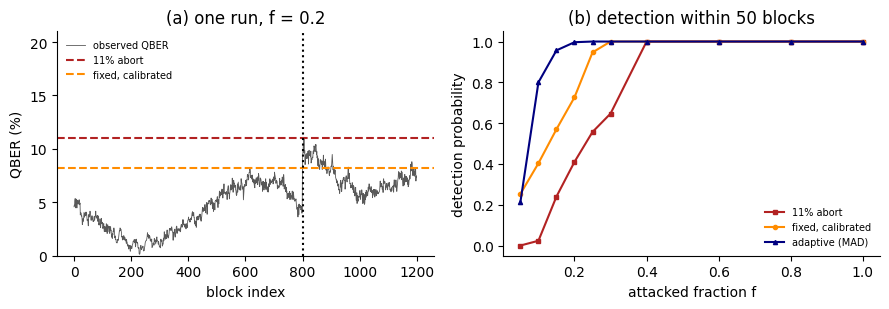

In [10]:
# Cell 7: quick-look figure
import matplotlib.pyplot as plt
S = results["strong"]; tr = traces["strong"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(tr*100, lw=0.6, color="0.35", label="observed QBER")
ax[0].axhline(11, color="firebrick", ls="--", label="11% abort")
ax[0].axhline(S["thr_fixed_calibrated"]*100, color="darkorange", ls="--", label="fixed, calibrated")
ax[0].axvline(COMMON["T_ATTACK"], color="k", ls=":"); ax[0].set_ylim(0, 21)
ax[0].set(xlabel="block index", ylabel="QBER (%)", title="(a) one run, f = 0.2"); ax[0].legend(frameon=False, fontsize=7, loc="upper left")
for key, lab, c, m in [("abort11", "11% abort", "firebrick", "s"), ("fixedFA", "fixed, calibrated", "darkorange", "o"), ("adaptive", "adaptive (MAD)", "navy", "^")]:
    ax[1].plot(S["f"], S[key], marker=m, ms=3, color=c, label=lab)
ax[1].set(xlabel="attacked fraction f", ylabel="detection probability", title="(b) detection within 50 blocks"); ax[1].legend(frameon=False, fontsize=7)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/qber_discrimination_preview.png", dpi=200); plt.show()

In [11]:
# Cell 8: check the output against the numbers quoted in the paper
def at(r, key, f): return r[key][[round(x, 2) for x in r["f"]].index(f)] * 100
PAPER = [  # (description, value computed here, value in the paper, tolerance in percentage points)
 ("strong: calibrated fixed threshold (%)", results["strong"]["thr_fixed_calibrated"]*100, 8.25, 0.05),
 ("strong f=0.10 adaptive (%)",            at(results["strong"], "adaptive", 0.10), 80, 1),
 ("strong f=0.10 fixed calibrated (%)",    at(results["strong"], "fixedFA", 0.10), 40, 1),
 ("strong f=0.10 11% abort (%)",           at(results["strong"], "abort11", 0.10), 2, 1),
 ("strong f=0.15 adaptive (%)",            at(results["strong"], "adaptive", 0.15), 96, 1),
 ("strong f=0.15 fixed calibrated (%)",    at(results["strong"], "fixedFA", 0.15), 57, 1),
 ("strong f=0.15 11% abort (%)",           at(results["strong"], "abort11", 0.15), 24, 1),
 ("mild f=0.10 fixed calibrated (%)",      at(results["mild"], "fixedFA", 0.10), 95, 1),
 ("mild f=0.10 adaptive (%)",              at(results["mild"], "adaptive", 0.10), 73, 1),
 ("strong f=0.05: best detector (%) ~ 25", max(at(results["strong"], k, 0.05) for k in ("abort11", "fixedFA", "adaptive")), 25, 1),
]
chk = pd.DataFrame(PAPER, columns=["claim", "computed", "paper", "tol"])
chk["ok"] = (chk.computed - chk.paper).abs() <= chk.tol
chk.to_csv(f"{OUT}/claims_check.csv", index=False); display(chk.round(2))
print("ALL MATCH" if chk.ok.all() else "SOME CLAIMS DO NOT MATCH: update the paper or the parameters")

,claim,computed,paper,tol,ok
0,strong: calibrated fixed threshold (%),8.25,8.25,0.05,True
1,strong f=0.10 adaptive (%),80.00,80.00,1.00,True
2,strong f=0.10 fixed calibrated (%),40.33,40.00,1.00,True
3,strong f=0.10 11% abort (%),2.33,2.00,1.00,True
4,strong f=0.15 adaptive (%),95.67,96.00,1.00,True
5,strong f=0.15 fixed calibrated (%),57.00,57.00,1.00,True
6,strong f=0.15 11% abort (%),24.00,24.00,1.00,True
7,mild f=0.10 fixed calibrated (%),94.67,95.00,1.00,True
8,mild f=0.10 adaptive (%),73.00,73.00,1.00,True
9,strong f=0.05: best detector (%) ~ 25,25.33,25.00,1.00,True


ALL MATCH


In [12]:
# Cell 9: download everything
try:
    from google.colab import files
    with zipfile.ZipFile("simulation_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for root, _, fs in os.walk(OUT):
            for f in fs: z.write(os.path.join(root, f))
    files.download("simulation_results.zip")
except ImportError:
    print("Not running in Colab: results are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>